# College majors and earnings: PCA Analysis

**Dataset:** `recent-grads(1).csv` (provided in the downloadable ZIP as `recent-grads-data.csv`)  
**Algorithm:** Principal Component Analysis (**PCA**)  
**Problem:** Can the economic outcomes of college majors be summarized using two or three numbers? Which majors pay well but offer weaker job security, and which show the reverse pattern?

This notebook uses eight economic measures, compares the information retained by two and three principal components, and creates three easy-to-compare PCA indexes: **Pay, Job Security, and Job Quality**. It then finds majors with opposite Pay and Job Security rankings. The indexes describe *relative* patterns in the provided historical data, not future individual outcomes.


## 1. Import required libraries

Run the following once if needed in a fresh Python environment: `pip install numpy pandas matplotlib scikit-learn notebook`

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option("display.max_colwidth", 58)
pd.set_option("display.width", 150)

print("PCA libraries loaded successfully.")

PCA libraries loaded successfully.


## 2. Load the dataset

Keep `recent-grads-data.csv` in the same folder as this notebook. The original uploaded filenames are also supported.


In [ ]:
candidate_files = [
    Path("recent-grads-data.csv"),
    Path("recent-grads(1).csv"),
    Path("recent-grads.csv"),
    Path("/mnt/data/recent-grads-data.csv"),
    Path("/mnt/data/recent-grads(1).csv"),
]
found = [p for p in candidate_files if p.exists()]
if not found:
    raise FileNotFoundError("Place recent-grads-data.csv in the same folder as this notebook.")
DATASET_PATH = found[0]
raw = pd.read_csv(DATASET_PATH)

print(f"Dataset used: {DATASET_PATH.name}")
print(f"Rows (majors): {raw.shape[0]}, columns: {raw.shape[1]}")
print("Columns:", ", ".join(raw.columns))
print("\nMissing values (only columns with missing data):")
print(raw.isna().sum()[lambda s: s > 0].to_string())
display(raw.head(5))


Dataset used: recent-grads-data.csv
Rows (majors): 173, columns: 21
Columns: Rank, Major_code, Major, Total, Men, Women, Major_category, ShareWomen, Sample_size, Employed, Full_time, Part_time, Full_time_year_round, Unemployed, Unemployment_rate, Median, P25th, P75th, College_jobs, Non_college_jobs, Low_wage_jobs

Missing values (only columns with missing data):
Total         1
Men           1
Women         1
ShareWomen    1


,Rank,Major_code,Major,Total,Men,Women,Major_category,ShareWomen,Sample_size,Employed,Full_time,Part_time,Full_time_year_round,Unemployed,Unemployment_rate,Median,P25th,P75th,College_jobs,Non_college_jobs,Low_wage_jobs
0,1,2419,PETROLEUM ENGINEERING,2339.0,2057.0,282.0,Engineering,0.120564,36,1976,1849,270,1207,37,0.018381,110000,95000,125000,1534,364,193
1,2,2416,MINING AND MINERAL ENGINEERING,756.0,679.0,77.0,Engineering,0.101852,7,640,556,170,388,85,0.117241,75000,55000,90000,350,257,50
2,3,2415,METALLURGICAL ENGINEERING,856.0,725.0,131.0,Engineering,0.153037,3,648,558,133,340,16,0.024096,73000,50000,105000,456,176,0
3,4,2417,NAVAL ARCHITECTURE AND MARINE ENGINEERING,1258.0,1123.0,135.0,Engineering,0.107313,16,758,1069,150,692,40,0.050125,70000,43000,80000,529,102,0
4,5,2405,CHEMICAL ENGINEERING,32260.0,21239.0,11021.0,Engineering,0.341631,289,25694,23170,5180,16697,1672,0.061098,65000,50000,75000,18314,4440,972


## 3. Prepare economic indicators

Counts cannot be compared directly because majors differ in size. I use earnings and employment-related ratios instead.

| Measure | Calculation | Better direction |
|---|---|---|
| Median earnings | `Median` | Higher |
| Lower-range earnings | `P25th` | Higher |
| Upper-range earnings | `P75th` | Higher |
| Unemployment | `Unemployment_rate` | Lower |
| Full-time, year-round employment indicator | `Full_time_year_round / Employed` | Higher |
| Part-time work indicator | `Part_time / (Full_time + Part_time)` | Lower |
| College-level job indicator | `College_jobs / Employed` | Higher |
| Low-wage job indicator | `Low_wage_jobs / Employed` | Lower |

**Data-quality check:** In the supplied data, `Full_time + Part_time` exceeds `Employed` for all 173 majors. These published counts therefore do not form an exact partition of `Employed`. To avoid labeling `Part_time / Employed` as a share of all employed graduates, I calculate the part-time indicator relative to the **reported full-time and part-time counts combined**. The employment-related ratios should still be treated as approximate indicators, not individual probabilities.

The `MILITARY TECHNOLOGIES` row has `Employed = 0`, making several ratios undefined, so it is excluded from the PCA. Full-time/year-round employment reflects work regularity; it does not prove job tenure or contract security.


In [ ]:
required = ["Major", "Major_category", "Sample_size", "Employed", "Full_time", "Part_time",
            "Median", "P25th", "P75th", "Unemployment_rate", "Full_time_year_round",
            "College_jobs", "Low_wage_jobs"]
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError("Required dataset columns are missing: " + ", ".join(missing_columns))

# Inspect the non-additive work-pattern counts before creating ratios.
non_additive = (raw["Full_time"] + raw["Part_time"] > raw["Employed"]).sum()
print(f"Non-additive Full_time + Part_time counts: {non_additive} of {len(raw)} majors")

work = raw.copy()
work = work.loc[(work["Employed"] > 0) &
                ((work["Full_time"] + work["Part_time"]) > 0)].copy()
work["Full_year_round_share"] = work["Full_time_year_round"] / work["Employed"]
work["Part_time_share"] = work["Part_time"] / (work["Full_time"] + work["Part_time"])
work["College_job_share"] = work["College_jobs"] / work["Employed"]
work["Low_wage_job_share"] = work["Low_wage_jobs"] / work["Employed"]

FEATURES = ["Median", "P25th", "P75th", "Unemployment_rate", "Full_year_round_share",
            "Part_time_share", "College_job_share", "Low_wage_job_share"]
work[FEATURES] = work[FEATURES].replace([np.inf, -np.inf], np.nan)
work = work.dropna(subset=FEATURES).reset_index(drop=True)

assert work[FEATURES].notna().all().all(), "PCA features still contain missing values"
assert work["Unemployment_rate"].between(0, 1).all()
assert work[["Full_year_round_share", "Part_time_share", "College_job_share",
             "Low_wage_job_share"]].ge(0).all().all()
assert work[["Full_year_round_share", "Part_time_share", "College_job_share",
             "Low_wage_job_share"]].le(1).all().all()
assert ((work["P25th"] <= work["Median"]) & (work["Median"] <= work["P75th"])).all()

print(f"Original majors: {len(raw)}")
print(f"Majors included in PCA: {len(work)}")
print(f"Excluded majors: {len(raw) - len(work)}")
print("Example economic features:")
display(work[["Major", "Median", "Unemployment_rate", "Full_year_round_share",
              "Part_time_share", "College_job_share", "Low_wage_job_share"]].head().round(3))


Non-additive Full_time + Part_time counts: 172 of 173 majors
Original majors: 173
Majors included in PCA: 172
Excluded majors: 1
Example economic features:


,Major,Median,Unemployment_rate,Full_year_round_share,Part_time_share,College_job_share,Low_wage_job_share
0,PETROLEUM ENGINEERING,110000,0.018,0.611,0.127,0.776,0.098
1,MINING AND MINERAL ENGINEERING,75000,0.117,0.606,0.234,0.547,0.078
2,METALLURGICAL ENGINEERING,73000,0.024,0.525,0.192,0.704,0.000
3,NAVAL ARCHITECTURE AND MARINE ENGINEERING,70000,0.050,0.913,0.123,0.698,0.000
4,CHEMICAL ENGINEERING,65000,0.061,0.650,0.183,0.713,0.038


## 4. Overall PCA: Are 2 or 3 components enough?

PCA is sensitive to feature scales. We therefore **standardize** every feature to a mean of zero and a standard deviation of one, then fit PCA. We inspect *explained variance* rather than assuming that 2 or 3 numbers are sufficient.

For orientation, we reverse the signs of the undesirable outcomes (unemployment, part-time, and low-wage shares) so **larger values always mean better outcomes**. This sign choice does not change explained-variance ratios.

Overall PCA: 2 components explain 65.1% of variation.
Overall PCA: 3 components explain 81.1% of variation.
Remaining after 3 components: 18.9%.


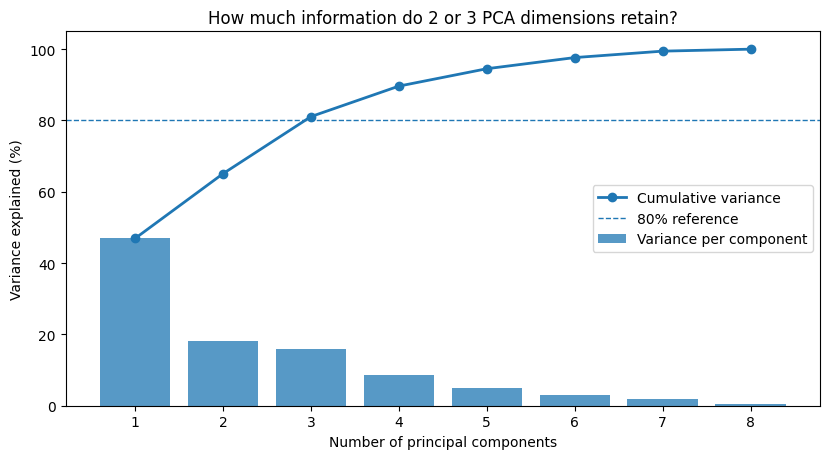

In [ ]:
directions = {
    "Median": 1, "P25th": 1, "P75th": 1,
    "Unemployment_rate": -1,
    "Full_year_round_share": 1,
    "Part_time_share": -1,
    "College_job_share": 1,
    "Low_wage_job_share": -1,
}

X_oriented = work[FEATURES].copy()
for col in FEATURES:
    X_oriented[col] *= directions[col]

standardizer = StandardScaler()
X_std = standardizer.fit_transform(X_oriented)
full_pca = PCA().fit(X_std)
variance = full_pca.explained_variance_ratio_
cumulative = np.cumsum(variance)

print(f"Overall PCA: 2 components explain {cumulative[1]:.1%} of variation.")
print(f"Overall PCA: 3 components explain {cumulative[2]:.1%} of variation.")
print(f"Remaining after 3 components: {1-cumulative[2]:.1%}.")

fig, ax = plt.subplots(figsize=(8.4, 4.7))
positions = np.arange(1, len(variance) + 1)
ax.bar(positions, variance * 100, alpha=.75, label="Variance per component")
ax.plot(positions, cumulative * 100, marker="o", linewidth=2, label="Cumulative variance")
ax.axhline(80, linestyle="--", linewidth=1, label="80% reference")
ax.set(xlabel="Number of principal components", ylabel="Variance explained (%)",
       title="How much information do 2 or 3 PCA dimensions retain?")
ax.set_xticks(positions)
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

## 5. Interpret the first 3 overall PCA components

**Loadings** show how strongly each feature contributes to a principal component. A component is a statistical direction, not automatically a clear concept like “salary” or “security.” We therefore use separate within-domain PCAs in the next section to build clearly named indexes.

,Overall PC1,Overall PC2,Overall PC3
Median,0.458,-0.300,-0.168
P25th,0.435,-0.267,-0.164
P75th,0.412,-0.350,-0.197
Unemployment_rate,0.140,0.171,0.632
Full_year_round_share,0.302,0.589,-0.233
Part_time_share,0.362,0.513,-0.110
College_job_share,0.232,-0.222,0.585
Low_wage_job_share,0.368,0.166,0.313


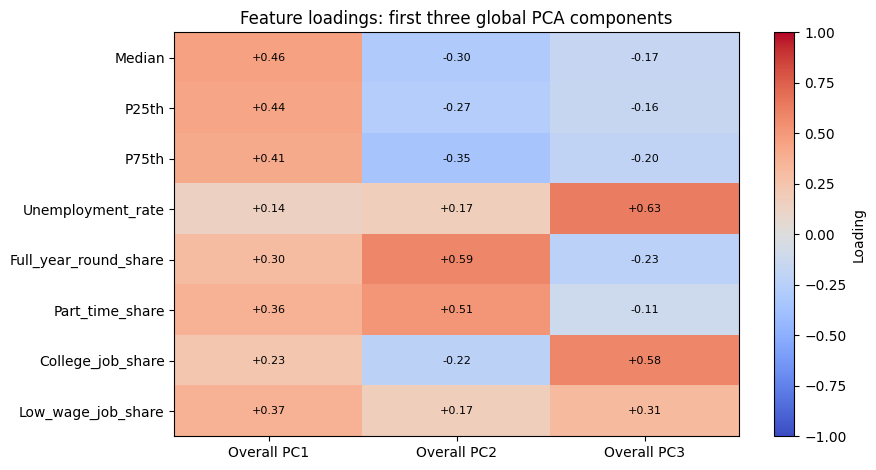

In [ ]:
overall_loading = pd.DataFrame(
    full_pca.components_[:3].T,
    index=FEATURES,
    columns=["Overall PC1", "Overall PC2", "Overall PC3"]
)
display(overall_loading.round(3))

fig, ax = plt.subplots(figsize=(9, 4.8))
img = ax.imshow(overall_loading.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(np.arange(3), overall_loading.columns)
ax.set_yticks(np.arange(len(FEATURES)), overall_loading.index)
ax.set_title("Feature loadings: first three global PCA components")
for i in range(len(FEATURES)):
    for j in range(3):
        ax.text(j, i, f"{overall_loading.iloc[i,j]:+.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(img, ax=ax, label="Loading")
plt.tight_layout()
plt.show()

## 6. Create three interpretable PCA indexes

I run a **one-component PCA in each domain** to create three scores per major:

- **Pay:** median earnings plus the 25th and 75th earnings percentiles.
- **Job Security:** unemployment and indicators of regular versus part-time work.
- **Job Quality:** college-level employment and low-wage employment indicators.

I standardize the variables and reverse undesirable outcomes so that higher values indicate better outcomes. Each PCA score is converted to a **within-dataset percentile (0–100)**. These are **relative rankings**, not percentages or job-probability estimates. The Security index emphasizes work regularity; the unemployment rate should also be inspected separately. The three domain indexes are **not the same as** the first three components of the overall PCA.


In [ ]:
GROUPS = {
    "Pay": ["Median", "P25th", "P75th"],
    "Security": ["Unemployment_rate", "Full_year_round_share", "Part_time_share"],
    "JobQuality": ["College_job_share", "Low_wage_job_share"],
}

models = {}
loadings = {}
explained = {}
for label, columns in GROUPS.items():
    oriented = work[columns].copy()
    for col in columns:
        oriented[col] *= directions[col]
    group_scaled = StandardScaler().fit_transform(oriented)
    model = PCA(n_components=1)
    component = model.fit_transform(group_scaled).ravel()
    weights = model.components_[0].copy()

    # PCA's sign is arbitrary. Align it with "higher is better" for the oriented features.
    favorable_anchor = group_scaled.mean(axis=1)
    if np.corrcoef(component, favorable_anchor)[0, 1] < 0:
        component = -component
        weights = -weights

    work[f"{label}_score"] = component
    work[f"{label}_index"] = work[f"{label}_score"].rank(method="average", pct=True) * 100
    explained[label] = float(model.explained_variance_ratio_[0])
    loadings[label] = pd.Series(weights, index=columns)
    models[label] = model

print("Variance explained by the first PCA component in each domain:")
for k, v in explained.items():
    print(f"  {k:>10}: {v:.1%}")
print("\nDomain PCA loadings (features are oriented as 'higher is better'):")
for k, v in loadings.items():
    print(f"{k:>10}: " + ", ".join(f"{column}={weight:+.3f}" for column, weight in v.items()))
print("\nIndex correlations:")
display(work[["Pay_index", "Security_index", "JobQuality_index"]].corr().round(3))

display(work[["Major", "Median", "Unemployment_rate", "Pay_index", "Security_index",
              "JobQuality_index"]].head().round(2))

Variance explained by the first PCA component in each domain:
         Pay: 89.9%
    Security: 62.8%
  JobQuality: 73.5%

Domain PCA loadings (features are oriented as 'higher is better'):
       Pay: Median=+0.600, P25th=+0.565, P75th=+0.567
  Security: Unemployment_rate=+0.237, Full_year_round_share=+0.678, Part_time_share=+0.696
JobQuality: College_job_share=+0.707, Low_wage_job_share=+0.707

Index correlations:


,Pay_index,Security_index,JobQuality_index
Pay_index,1.000,0.430,0.417
Security_index,0.430,1.000,0.381
JobQuality_index,0.417,0.381,1.000


,Major,Median,Unemployment_rate,Pay_index,Security_index,JobQuality_index
0,PETROLEUM ENGINEERING,110000,0.02,100.00,81.98,86.05
1,MINING AND MINERAL ENGINEERING,75000,0.12,98.84,42.44,68.60
2,METALLURGICAL ENGINEERING,73000,0.02,99.42,55.23,98.84
3,NAVAL ARCHITECTURE AND MARINE ENGINEERING,70000,0.05,97.67,98.26,98.26
4,CHEMICAL ENGINEERING,65000,0.06,97.09,69.19,93.02


## 7. Compare majors with opposite pay and security rankings

I use a consistent rule: high pay / low security means **Pay ≥ 75** and **Security ≤ 25**; the reverse means **Pay ≤ 25** and **Security ≥ 75**. These cutoffs identify relative quartiles, not absolute career judgments. Results based on fewer than 30 survey observations are flagged for caution.


In [ ]:
work["Low_sample_flag"] = work["Sample_size"] < 30
high_pay_low_security = work.loc[(work["Pay_index"] >= 75) & (work["Security_index"] <= 25)].copy()
low_pay_high_security = work.loc[(work["Pay_index"] <= 25) & (work["Security_index"] >= 75)].copy()

REPORT_COLS = ["Major", "Major_category", "Sample_size", "Median", "Unemployment_rate",
               "Full_year_round_share", "Part_time_share", "Pay_index", "Security_index", "JobQuality_index"]

def show_cases(title, selected, sort_by, ascending):
    print(f"\n{title} — {len(selected)} majors; {sum(selected['Sample_size'] >= 30)} have sample size >= 30")
    if len(selected):
        display(selected.sort_values(sort_by, ascending=ascending)[REPORT_COLS].round(3))
    else:
        print("No majors meet both strict thresholds.")

show_cases("HIGH PAY + LOW SECURITY", high_pay_low_security, "Pay_index", False)
show_cases("LOW PAY + HIGH SECURITY", low_pay_high_security, "Security_index", False)


HIGH PAY + LOW SECURITY — 3 majors; 2 have sample size >= 30


,Major,Major_category,Sample_size,Median,Unemployment_rate,Full_year_round_share,Part_time_share,Pay_index,Security_index,JobQuality_index
21,FOOD SCIENCE,Agriculture & Natural Resources,36,53000,0.097,0.551,0.305,86.047,22.093,32.558
23,MATERIALS ENGINEERING AND MATERIALS SCIENCE,Engineering,22,52000,0.028,0.470,0.385,82.558,11.047,97.093
32,MISCELLANEOUS FINE ARTS,Arts,30,50000,0.089,0.412,0.342,75.000,4.070,2.326



LOW PAY + HIGH SECURITY — 3 majors; 2 have sample size >= 30


,Major,Major_category,Sample_size,Median,Unemployment_rate,Full_year_round_share,Part_time_share,Pay_index,Security_index,JobQuality_index
142,PLANT SCIENCE AND AGRONOMY,Agriculture & Natural Resources,110,32000,0.045,0.686,0.177,15.698,80.233,13.953
89,GEOSCIENCES,Physical Sciences,18,36000,0.024,0.702,0.219,22.093,77.326,49.419
153,TEACHER EDUCATION: MULTIPLE LEVELS,Education,142,30000,0.037,0.647,0.159,12.209,76.744,95.349


## 8. Visualize the Pay–Security trade-off

Each dot is a major. Its color shows Job Quality, and its size reflects the survey sample size (capped for readability). Dashed lines indicate the 25th and 75th percentile index cutoffs.


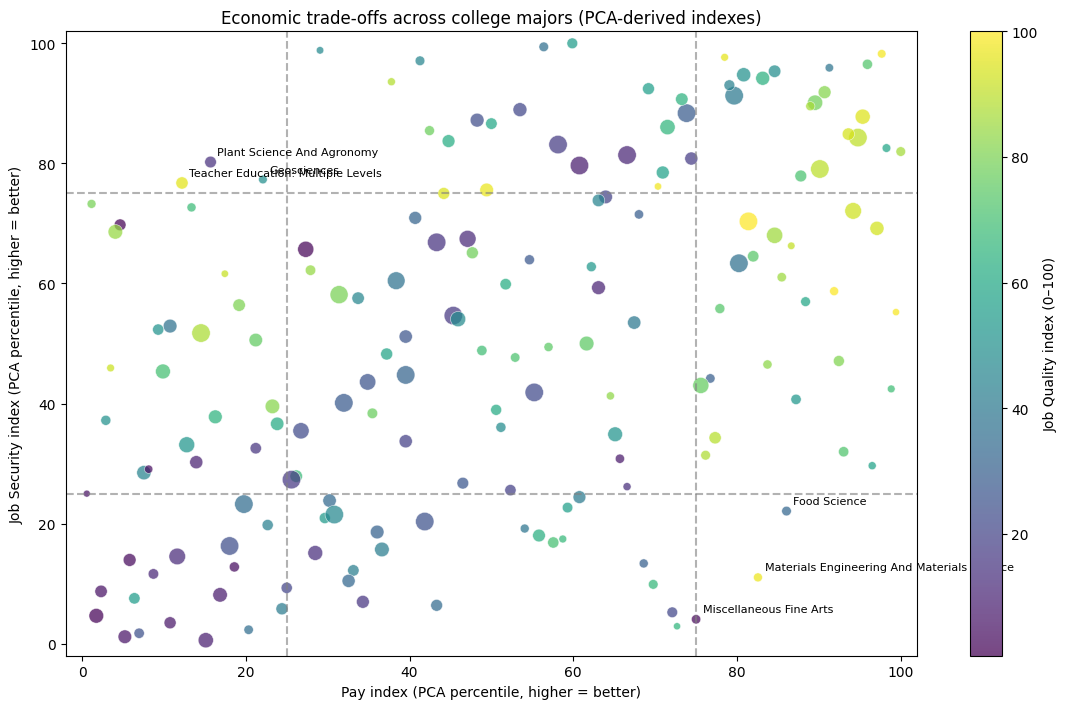

In [ ]:
fig, ax = plt.subplots(figsize=(11.5, 7.2))
size = 18 + 5 * np.sqrt(work["Sample_size"].clip(lower=0, upper=1000))
scatter = ax.scatter(work["Pay_index"], work["Security_index"], c=work["JobQuality_index"],
                     s=size, cmap="viridis", alpha=.72, edgecolors="white", linewidths=.45)
for cutoff in (25, 75):
    ax.axvline(cutoff, linestyle="--", color="gray", alpha=.6)
    ax.axhline(cutoff, linestyle="--", color="gray", alpha=.6)

cases_to_label = pd.concat([high_pay_low_security, low_pay_high_security]).drop_duplicates(subset=["Major"])
for _, r in cases_to_label.iterrows():
    ax.annotate(r["Major"].title(), (r["Pay_index"], r["Security_index"]), xytext=(5, 5),
                textcoords="offset points", fontsize=8)
ax.set(xlim=(-2, 102), ylim=(-2, 102), xlabel="Pay index (PCA percentile, higher = better)",
       ylabel="Job Security index (PCA percentile, higher = better)",
       title="Economic trade-offs across college majors (PCA-derived indexes)")
cb = fig.colorbar(scatter, ax=ax)
cb.set_label("Job Quality index (0–100)")
plt.tight_layout()
plt.show()

## 9. Check unemployment separately

The Security index mostly reflects full-time/year-round versus part-time work, because these indicators receive larger PCA weights than unemployment. To avoid confusing **regular employment among workers** with **the chance of being unemployed**, I also show majors with both high Pay indexes and high reported unemployment rates.


In [ ]:
hi_median = work["Pay_index"].quantile(.75)
hi_unemployment = work["Unemployment_rate"].quantile(.75)
jobless_risk_check = work.loc[
    (work["Pay_index"] >= hi_median) & (work["Unemployment_rate"] >= hi_unemployment),
    ["Major", "Sample_size", "Median", "Unemployment_rate", "Full_year_round_share", "Pay_index", "Security_index"]
].sort_values("Unemployment_rate", ascending=False)
print(f"Top-quartile Pay and top-quartile unemployment (rate >= {hi_unemployment:.1%}):")
display(jobless_risk_check.round(3))

Top-quartile Pay and top-quartile unemployment (rate >= 8.8%):


,Major,Sample_size,Median,Unemployment_rate,Full_year_round_share,Pay_index,Security_index
5,NUCLEAR ENGINEERING,17,65000,0.177,0.780,98.256,82.558
29,PUBLIC POLICY,55,50000,0.128,0.611,87.209,40.698
1,MINING AND MINERAL ENGINEERING,7,75000,0.117,0.606,98.837,42.442
36,ECONOMICS,1322,47000,0.099,0.679,80.233,63.372
21,FOOD SCIENCE,36,53000,0.097,0.551,86.047,22.093
6,ACTUARIAL SCIENCE,51,62000,0.096,0.852,95.930,96.512
30,ENVIRONMENTAL ENGINEERING,26,50000,0.094,0.654,83.721,46.512
12,BIOMEDICAL ENGINEERING,79,60000,0.092,0.596,92.442,47.093
47,APPLIED MATHEMATICS,45,45000,0.091,0.673,77.907,55.814


## 10. Results summary

This short code cell summarizes the final PCA results and the majors identified by the two ranking rules.


In [ ]:
print(f"Dataset: {DATASET_PATH.name} ({len(work)} majors analyzed, out of {len(raw)})")
print(f"Algorithm: PCA | 2 components: {cumulative[1]:.1%} variance | 3 components: {cumulative[2]:.1%} variance")
print(f"Within-domain variance (first PC): Pay {explained['Pay']:.1%}, Security {explained['Security']:.1%}, Quality {explained['JobQuality']:.1%}")

def brief_cases(df):
    if df.empty:
        return "None met the thresholds"
    return "; ".join(
        f"{r['Major'].title()} (${r['Median']:,.0f} median" +
        (", small sample" if r["Sample_size"] < 30 else "") + ")"
        for _, r in df.iterrows()
    )

print("High pay / lower security: " + brief_cases(high_pay_low_security))
print("Lower pay / higher security: " + brief_cases(low_pay_high_security))


Dataset: recent-grads-data.csv (172 majors analyzed, out of 173)
Algorithm: PCA | 2 components: 65.1% variance | 3 components: 81.1% variance
Within-domain variance (first PC): Pay 89.9%, Security 62.8%, Quality 73.5%
High pay / lower security: Food Science ($53,000 median); Materials Engineering And Materials Science ($52,000 median, small sample); Miscellaneous Fine Arts ($50,000 median)
Lower pay / higher security: Geosciences ($36,000 median, small sample); Plant Science And Agronomy ($32,000 median); Teacher Education: Multiple Levels ($30,000 median)


## Conclusion

I ran PCA on eight economic measures and found that two overall principal components explained 65.1% of the variation, compared with 81.1% for three. To make the results easier to understand, I also created three separate PCA-based indexes for Pay, Job Security, and Job Quality. Food Science had relatively high pay but weaker job security, while Plant Science and Agronomy had lower pay but more regular employment. This tells me that salary alone does not show the whole picture of a major’s economic outcomes. Because some majors have small samples and job security is only an approximate measure here, I would check the original numbers before making a decision.
